# Low-bit LLM quantization on a T4

Weight-only quantization of Qwen2.5-1.5B on a Colab T4. I compare my own RTN, GPTQ and AWQ implementations, then run the quantized weights through Triton kernels I wrote (`w4a16.py`) and measure accuracy, memory and decode speed against fp16 and bitsandbytes.

Files that need to sit next to this notebook: `w4a16.py`, `ptq.py`, `decode_bench.py`, and the `test_*.py` files.

In [1]:
%pip install -q transformers datasets accelerate lm-eval bitsandbytes pandas matplotlib tabulate
# torch and triton ship with the Colab runtime; don't upgrade them here.

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.1/64.1 kB 2.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 37.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 15.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.1/91.1 kB 7.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.6/129.6 kB 6.5 MB/s eta 0:00:00


In [2]:
import os, gc, re, time, json, math, random, importlib
from functools import partial
import numpy as np
import pandas as pd
import torch, torch.nn as nn
import torch.nn.functional as F
import transformers
import matplotlib.pyplot as plt
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig
from datasets import load_dataset
import triton

assert torch.cuda.is_available(), "Need a GPU runtime"
import w4a16, ptq, decode_bench as db
print("torch", torch.__version__, "| transformers", transformers.__version__, "| triton", triton.__version__)
print(torch.cuda.get_device_name(0), "| compute capability", torch.cuda.get_device_capability(0))

torch 2.11.0+cu130 | transformers 5.18.0 | triton 3.6.0
Tesla T4 | compute capability (7, 5)


In [3]:
# config
MODEL_ID    = "Qwen/Qwen2.5-1.5B"
FALLBACK_ID = "meta-llama/Llama-3.2-1B"   # gated; use if Qwen gives NaNs in fp16
DTYPE       = torch.float16               # T4 has no bf16
SEED        = 0

PPL_SEQLEN        = 2048
LM_EVAL_TASKS     = ["arc_easy", "hellaswag"]
LM_EVAL_LIMIT     = 1000                  # examples per task (std-error ~1.5 points); None = full set (slow)
LM_EVAL_BATCH     = 8
DECODE_PROMPT_LEN = 128
DECODE_NEW_TOKENS = 128
DECODE_REPEATS    = 3

CALIB_N, CALIB_SEQLEN, CALIB_BATCH = 128, 512, 8   # GPTQ / AWQ calibration: 128 x 512 tokens of WikiText-2 *train*
GROUP = 128

RUN_GPTQ, RUN_AWQ, RUN_ABLATIONS, RUN_KERNEL_SWEEP = True, True, True, True

T4_PEAK_GBPS   = 320                      # DRAM bandwidth
T4_PEAK_TFLOPS = 65                       # fp16 tensor-core peak
RESUME         = True

USE_DRIVE = False                         # True: results / packed weights / figures go to Google Drive (survive resets)
OUT = "."
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT = "/content/drive/MyDrive/quant_llm_results"
os.makedirs(f"{OUT}/figures", exist_ok=True)
RESULTS_JSON = f"{OUT}/results_v2.json"
print("outputs ->", os.path.abspath(OUT))

outputs -> /content


## 0. Eval setup and fp16 baseline

- Perplexity: WikiText-2 test set, non-overlapping 2048-token windows.
- ARC-Easy (acc) and HellaSwag (acc_norm) through lm-eval, zero-shot, 1000 examples each. The standard error is about 0.014, so I don't read much into differences below ~0.03.
- Weights GB: measured with `get_memory_footprint()` when the weights are actually stored quantized, otherwise the size they would take once packed.
- Est. peak GB: weights plus the extra memory allocated during the perplexity pass. It's measured as a difference, so the fp16 backup copy I keep on the GPU doesn't count.
- Decode tok/s: greedy `generate`, timed as (1 + 128 new tokens) minus (1 new token), which takes prefill out.

In [4]:
def free():
    gc.collect(); torch.cuda.empty_cache()

def seed_all(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def hf_load(path, **kw):
    try:
        return AutoModelForCausalLM.from_pretrained(path, dtype=DTYPE, **kw)
    except TypeError:                                   # older transformers: torch_dtype
        return AutoModelForCausalLM.from_pretrained(path, torch_dtype=DTYPE, **kw)

def load_fp16(model_id=MODEL_ID):
    tok = AutoTokenizer.from_pretrained(model_id)
    model = hf_load(model_id, device_map={"": 0}).eval()   # straight to GPU: low CPU RAM
    return model, tok

@torch.no_grad()
def check_finite(model, tok):
    ids = tok("The quick brown fox jumps over the lazy dog. " * 20, return_tensors="pt").input_ids.cuda()
    ok = bool(torch.isfinite(model(ids).logits).all().item())
    print("finite fp16 logits:", ok)
    return ok

In [5]:
_WT2_CACHE = {}

@torch.no_grad()
def wikitext2_ppl(model, tok, seqlen=PPL_SEQLEN, max_windows=None):
    key = (tok.name_or_path, seqlen)
    if key not in _WT2_CACHE:
        test = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split="test")
        _WT2_CACHE[key] = tok("\n\n".join(test["text"]), return_tensors="pt").input_ids
    ids = _WT2_CACHE[key]
    n = ids.shape[1] // seqlen
    if max_windows:
        n = min(n, max_windows)
    nll, count = 0.0, 0
    for i in range(n):
        x = ids[:, i * seqlen:(i + 1) * seqlen].cuda()
        logits = model(x).logits[:, :-1].float()
        nll += F.cross_entropy(logits.reshape(-1, logits.size(-1)), x[:, 1:].reshape(-1), reduction="sum").item()
        count += x.shape[1] - 1
        del logits
    return math.exp(nll / count)


@torch.no_grad()
def decode_tps(model, tok, prompt_len=DECODE_PROMPT_LEN, new_tokens=DECODE_NEW_TOKENS, repeats=DECODE_REPEATS):
    g = torch.Generator().manual_seed(SEED)
    ids = torch.randint(1000, 30000, (1, prompt_len), generator=g).cuda()
    attn = torch.ones_like(ids)
    pad = tok.pad_token_id if tok.pad_token_id is not None else tok.eos_token_id

    def run(n):
        torch.cuda.synchronize(); t = time.perf_counter()
        model.generate(ids, attention_mask=attn, max_new_tokens=n, min_new_tokens=n, do_sample=False, pad_token_id=pad)
        torch.cuda.synchronize(); return time.perf_counter() - t

    run(4)                                               # warm-up (also triggers kernel autotune)
    t1 = min(run(1) for _ in range(repeats))
    tn = min(run(1 + new_tokens) for _ in range(repeats))
    return new_tokens / (tn - t1)


def run_lm_eval(model, tok, tasks=LM_EVAL_TASKS, limit=LM_EVAL_LIMIT, batch_size=LM_EVAL_BATCH):
    from lm_eval import evaluator
    from lm_eval.models.huggingface import HFLM
    lm = HFLM(pretrained=model, tokenizer=tok, batch_size=batch_size)
    out = evaluator.simple_evaluate(model=lm, tasks=tasks, limit=limit, num_fewshot=0,
                                    random_seed=SEED, numpy_random_seed=SEED, torch_random_seed=SEED)
    res = {}
    for t in tasks:
        r = out["results"][t]
        metric = "acc_norm" if t == "hellaswag" else "acc"
        name = t + ("_norm" if metric == "acc_norm" else "")
        res[name] = r.get(f"{metric},none")
        res[name + "_se"] = r.get(f"{metric}_stderr,none")
    return res

In [6]:
RESULTS = json.load(open(RESULTS_JSON)) if (RESUME and os.path.exists(RESULTS_JSON)) else []

def is_done(method, bits, group):
    g = str(group if group else "-")
    return any(r["method"] == method and r["bits"] == bits and str(r["group"]) == g for r in RESULTS)

def weights_gb_theoretical(model, bits, group_size, asym=True, skip=("lm_head",)):
    # packed size if deployed: quantized decoder linears at `bits` + fp16 scale (+ fp16 zero) per group;
    # everything else (embeddings, norms, skipped layers) fp16. Tied/shared tensors are counted once.
    total, quantized = 0.0, set()
    for name, m in model.named_modules():
        if isinstance(m, nn.Linear) and not any(s in name for s in skip):
            N, K = m.weight.shape
            gs = K if group_size in (-1, 0) else group_size
            total += N * K * bits / 8 + N * (K // gs) * 2 * (2 if asym else 1)
            quantized.add(id(m.weight))
            if m.bias is not None:
                total += m.bias.numel() * m.bias.element_size(); quantized.add(id(m.bias))
    for p in model.parameters():
        if id(p) not in quantized:
            total += p.numel() * p.element_size()
    return total / 1e9

def evaluate(name, model, tok, bits=16, group=None, weights_gb=None, lm_eval=True, decode=True, extra=None):
    seed_all(); free()
    torch.cuda.synchronize()
    base = torch.cuda.memory_allocated(); torch.cuda.reset_peak_memory_stats()
    ppl = wikitext2_ppl(model, tok)
    act_gb = (torch.cuda.max_memory_allocated() - base) / 1e9
    wgb = weights_gb if weights_gb is not None else model.get_memory_footprint() / 1e9
    row = dict(method=name, bits=bits, group=group if group else "-", ppl=round(ppl, 3),
               weights_gb=round(wgb, 3), est_peak_gb=round(wgb + act_gb, 2))
    if lm_eval:
        row.update({k: (round(v, 4) if v is not None else None) for k, v in run_lm_eval(model, tok).items()})
    row["decode_tok_s"] = round(decode_tps(model, tok), 1) if decode else float("nan")
    if extra:
        row.update(extra)
    RESULTS[:] = [r for r in RESULTS if not (r["method"] == name and r["bits"] == bits and str(r["group"]) == str(row["group"]))]
    RESULTS.append(row)
    json.dump(RESULTS, open(RESULTS_JSON, "w"), indent=1)
    print(row)
    return row

def results_df():
    return pd.DataFrame(RESULTS)

In [7]:
# fp16 baseline
model, tok = load_fp16()
if not check_finite(model, tok):
    raise RuntimeError("Non-finite fp16 logits: set MODEL_ID = FALLBACK_ID and re-run from the config cell.")
if not is_done("FP16", 16, None):
    evaluate("FP16", model, tok, bits=16)

# Load once and keep a copy of the fp16 weights on the GPU (~3 GB); restore() puts them back between experiments.
ORIG = {k: v.clone() for k, v in model.state_dict().items()}
def restore():
    model.load_state_dict(ORIG)
results_df()

config.json:   0%|          | 0.00/684 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

...

Map:   0%|          | 0/39905 [00:00<?, ? examples/s]

Map:   0%|          | 0/10042 [00:00<?, ? examples/s]

Running loglikelihood requests: 100%|██████████| 7997/7997 [01:17<00:00, 102.79it/s]


{'method': 'FP16', 'bits': 16, 'group': '-', 'ppl': 9.265, 'weights_gb': 3.087, 'est_peak_gb': 5.58, 'arc_easy': 0.751, 'arc_easy_se': 0.0137, 'hellaswag_norm': 0.583, 'hellaswag_norm_se': 0.0156, 'decode_tok_s': 24.6}


,method,bits,group,ppl,weights_gb,est_peak_gb,arc_easy,arc_easy_se,hellaswag_norm,hellaswag_norm_se,decode_tok_s
0,FP16,16,-,9.265,3.087,5.58,0.751,0.0137,0.583,0.0156,24.6


## 1. RTN

Group-wise round-to-nearest, applied as fake-quant. `lm_head` shares its weights with the embedding table in this model, so I leave it in fp16.

In [8]:
@torch.no_grad()
def rtn_fake_quant(w, bits=4, group_size=128, symmetric=False):
    # w: [N, K] (nn.Linear weight). group_size -1/0 => one group per output channel.
    N, K = w.shape
    gs = K if group_size in (-1, 0) else group_size
    assert K % gs == 0, f"K={K} not divisible by group_size={gs}"
    wg = w.float().reshape(N, K // gs, gs)
    if symmetric:
        qmax = 2 ** (bits - 1) - 1
        scale = (wg.abs().amax(-1, keepdim=True) / qmax).clamp(min=1e-8)
        q = torch.round(wg / scale).clamp(-qmax - 1, qmax)
        deq = q * scale
    else:
        qmax = 2 ** bits - 1
        mn, mx = wg.amin(-1, keepdim=True), wg.amax(-1, keepdim=True)
        scale = ((mx - mn) / qmax).clamp(min=1e-8)
        zero = torch.round(-mn / scale).clamp(0, qmax)
        q = torch.round(wg / scale + zero).clamp(0, qmax)
        deq = (q - zero) * scale
    return deq.reshape(N, K).to(w.dtype)


@torch.no_grad()
def quantize_model_rtn(model, bits=4, group_size=128, symmetric=False,
                       skip_names=("lm_head",), keep_fp16_layers=(), only=None):
    n = 0
    for name, m in model.named_modules():
        if not isinstance(m, nn.Linear) or any(s in name for s in skip_names):
            continue
        if only and not any(s in name for s in only):
            continue
        mt = re.search(r"layers\.(\d+)\.", name)
        if mt and int(mt.group(1)) in keep_fp16_layers:
            continue
        m.weight.data = rtn_fake_quant(m.weight.data, bits, group_size, symmetric)
        n += 1
    return n

In [9]:
# quick checks of rtn_fake_quant (runs on CPU)
torch.manual_seed(0)
Wt = torch.randn(64, 512) * 0.02
for bits in (4, 8):
    for gs in (32, 128, -1):
        for sym in (True, False):
            Wq = rtn_fake_quant(Wt, bits, gs, sym)
            g = 512 if gs == -1 else gs
            assert max(len(torch.unique(row)) for row in Wq.reshape(-1, g)) <= 2 ** bits
errs = {gs: ((rtn_fake_quant(Wt, 4, gs, False) - Wt) ** 2).mean().item() for gs in (-1, 128, 64, 32)}
print("4-bit asym MSE by group size:", errs)
assert errs[32] < errs[64] < errs[128] < errs[-1]
print("RTN tests passed")

4-bit asym MSE by group size: {-1: 5.523829713638406e-06, 128: 4.055023509863531e-06, 64: 3.294569296485861e-06, 32: 2.6302852802473353e-06}
RTN tests passed


In [10]:
# relative weight error on one real layer, for each setting
W = ORIG[f"model.layers.{model.config.num_hidden_layers // 2}.mlp.down_proj.weight"]
rows = []
for bits in (8, 4):
    for gs in (-1, 128, 64, 32):
        for sym in (True, False):
            Wq = rtn_fake_quant(W, bits, gs, sym)
            rel = ((Wq.float() - W.float()) ** 2).mean().item() / (W.float() ** 2).mean().item()
            rows.append(dict(bits=bits, group=gs, sym=sym, rel_mse=rel))
pd.DataFrame(rows).pivot_table(index=["bits", "group"], columns="sym", values="rel_mse").style.format("{:.2e}")

In [11]:
# RTN on the whole model (fake-quant, so accuracy only)
RTN_CONFIGS = [dict(bits=8, gs=128, sym=False), dict(bits=4, gs=128, sym=False),
               dict(bits=4, gs=128, sym=True), dict(bits=4, gs=-1, sym=False)]
for c in RTN_CONFIGS:
    label = "RTN-" + ("sym" if c["sym"] else "asym") + " (mine)"
    if is_done(label, c["bits"], c["gs"]):
        print("skip (done):", label, c); continue
    restore()
    quantize_model_rtn(model, c["bits"], c["gs"], c["sym"])
    evaluate(label, model, tok, bits=c["bits"], group=c["gs"],
             weights_gb=weights_gb_theoretical(model, c["bits"], c["gs"], asym=not c["sym"]), decode=False)
restore(); free()
results_df()

Running loglikelihood requests: 100%|██████████| 7997/7997 [01:23<00:00, 95.92it/s] 


{'method': 'RTN-asym (mine)', 'bits': 8, 'group': 128, 'ppl': 9.268, 'weights_gb': 1.818, 'est_peak_gb': 4.31, 'arc_easy': 0.743, 'arc_easy_se': 0.0138, 'hellaswag_norm': 0.582, 'hellaswag_norm_se': 0.0156, 'decode_tok_s': nan}


Running loglikelihood requests: 100%|██████████| 7997/7997 [01:18<00:00, 102.00it/s]


{'method': 'RTN-asym (mine)', 'bits': 4, 'group': 128, 'ppl': 10.36, 'weights_gb': 1.163, 'est_peak_gb': 3.65, 'arc_easy': 0.705, 'arc_easy_se': 0.0144, 'hellaswag_norm': 0.572, 'hellaswag_norm_se': 0.0157, 'decode_tok_s': nan}


Running loglikelihood requests: 100%|██████████| 7997/7997 [01:18<00:00, 101.90it/s]


{'method': 'RTN-sym (mine)', 'bits': 4, 'group': 128, 'ppl': 10.851, 'weights_gb': 1.143, 'est_peak_gb': 3.63, 'arc_easy': 0.719, 'arc_easy_se': 0.0142, 'hellaswag_norm': 0.576, 'hellaswag_norm_se': 0.0156, 'decode_tok_s': nan}


Running loglikelihood requests: 100%|██████████| 7997/7997 [01:17<00:00, 102.76it/s]


{'method': 'RTN-asym (mine)', 'bits': 4, 'group': -1, 'ppl': 13.505, 'weights_gb': 1.125, 'est_peak_gb': 3.61, 'arc_easy': 0.693, 'arc_easy_se': 0.0146, 'hellaswag_norm': 0.567, 'hellaswag_norm_se': 0.0157, 'decode_tok_s': nan}


,method,bits,group,ppl,weights_gb,est_peak_gb,arc_easy,arc_easy_se,hellaswag_norm,hellaswag_norm_se,decode_tok_s
0,FP16,16,-,9.265,3.087,5.58,0.751,0.0137,0.583,0.0156,24.6
1,RTN-asym (mine),8,128,9.268,1.818,4.31,0.743,0.0138,0.582,0.0156,NaN
2,RTN-asym (mine),4,128,10.360,1.163,3.65,0.705,0.0144,0.572,0.0157,NaN
3,RTN-sym (mine),4,128,10.851,1.143,3.63,0.719,0.0142,0.576,0.0156,NaN
4,RTN-asym (mine),4,-1,13.505,1.125,3.61,0.693,0.0146,0.567,0.0157,NaN


## 2. GPTQ, AWQ, bitsandbytes

GPTQ and AWQ are in `ptq.py`. Both calibrate on 128 random 512-token windows from the WikiText-2 train split, and both go layer by layer, so each layer is calibrated on inputs that already passed through the quantized layers before it.

GPTQ quantizes one column at a time and spreads each column's rounding error over the columns that haven't been quantized yet, weighted by the inverse Hessian of the layer inputs (H = 2XᵀX). The aim is to keep the layer's output close, not the individual weights.

AWQ multiplies each input channel of W by s = mean|x|^α before quantizing and divides the activations by s at run time, so channels with large activations get finer steps. α is picked by grid search for each group of linears that share an input (q/k/v, o, gate/up, down).

The packed weights are cached and reused in 4d. bitsandbytes NF4 and INT8 are here as library baselines.

In [12]:
def calib_ids(tok, n=CALIB_N, seqlen=CALIB_SEQLEN, seed=SEED):
    train = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split="train")
    ids = tok("\n\n".join(train["text"]), return_tensors="pt").input_ids[0]
    starts = np.random.RandomState(seed).randint(0, len(ids) - seqlen - 1, size=n)
    return torch.stack([ids[s:s + seqlen] for s in starts])

CALIB = calib_ids(tok)
print("calibration set:", tuple(CALIB.shape))

PACKED = {}
def packed_path(key):
    return f"{OUT}/packed_{key}.pt"

def get_packed(key):
    if key not in PACKED and os.path.exists(packed_path(key)):
        PACKED[key] = torch.load(packed_path(key))
    return PACKED.get(key)

calibration set: (128, 512)


In [13]:
def run_ptq(key, label, fn):
    """Quantize with fn(model) -> packed results, cache them, evaluate the fake-quant model."""
    if is_done(label, 4, GROUP) and get_packed(key) is not None:
        print("skip (done):", label); return
    restore(); free()
    t0 = time.time()
    res = fn(model)
    qtime = time.time() - t0
    torch.save(res, packed_path(key)); PACKED[key] = res
    if not is_done(label, 4, GROUP):
        evaluate(label, model, tok, bits=4, group=GROUP, weights_gb=weights_gb_theoretical(model, 4, GROUP),
                 decode=False, extra=dict(quant_time_s=round(qtime)))
    restore(); free()

if RUN_GPTQ:
    run_ptq("gptq", "GPTQ (mine)", lambda m: ptq.gptq_quantize_model(m, CALIB, GROUP, batch_size=CALIB_BATCH))
if RUN_AWQ:
    run_ptq("awq", "AWQ (mine)", lambda m: ptq.awq_quantize_model(m, CALIB, GROUP, batch_size=CALIB_BATCH))
results_df()

GPTQ layer 1/28 done
GPTQ layer 2/28 done
GPTQ layer 3/28 done
GPTQ layer 4/28 done
GPTQ layer 5/28 done
GPTQ layer 6/28 done
GPTQ layer 7/28 done
GPTQ layer 8/28 done
GPTQ layer 9/28 done
GPTQ layer 10/28 done
GPTQ layer 11/28 done
GPTQ layer 12/28 done
GPTQ layer 13/28 done
GPTQ layer 14/28 done
GPTQ layer 15/28 done
GPTQ layer 16/28 done
GPTQ layer 17/28 done
GPTQ layer 18/28 done
GPTQ layer 19/28 done
GPTQ layer 20/28 done
GPTQ layer 21/28 done
GPTQ layer 22/28 done
GPTQ layer 23/28 done
GPTQ layer 24/28 done
GPTQ layer 25/28 done
GPTQ layer 26/28 done
GPTQ layer 27/28 done
GPTQ layer 28/28 done


Running loglikelihood requests: 100%|██████████| 7997/7997 [01:17<00:00, 102.64it/s]


{'method': 'GPTQ (mine)', 'bits': 4, 'group': 128, 'ppl': 9.844, 'weights_gb': 1.163, 'est_peak_gb': 3.65, 'arc_easy': 0.75, 'arc_easy_se': 0.0137, 'hellaswag_norm': 0.578, 'hellaswag_norm_se': 0.0156, 'decode_tok_s': nan, 'quant_time_s': 496}
AWQ layer 1/28 self_attn.q_proj+self_attn.k_proj+self_attn.v_proj: alpha=0.25
AWQ layer 1/28 self_attn.o_proj: alpha=0.40
AWQ layer 1/28 mlp.gate_proj+mlp.up_proj: alpha=0.30
AWQ layer 1/28 mlp.down_proj: alpha=0.45
AWQ layer 2/28 self_attn.q_proj+self_attn.k_proj+self_attn.v_proj: alpha=0.30
AWQ layer 2/28 self_attn.o_proj: alpha=0.45
AWQ layer 2/28 mlp.gate_proj+mlp.up_proj: alpha=0.35
AWQ layer 2/28 mlp.down_proj: alpha=0.90
AWQ layer 3/28 self_attn.q_proj+self_attn.k_proj+self_attn.v_proj: alpha=0.30
AWQ layer 3/28 self_attn.o_proj: alpha=0.35
AWQ layer 3/28 mlp.gate_proj+mlp.up_proj: alpha=0.35
AWQ layer 3/28 mlp.down_proj: alpha=1.00
AWQ layer 4/28 self_attn.q_proj+self_attn.k_proj+self_attn.v_proj: alpha=0.35
AWQ layer 4/28 self_attn.o_pro

Running loglikelihood requests: 100%|██████████| 7997/7997 [01:18<00:00, 101.67it/s]


{'method': 'AWQ (mine)', 'bits': 4, 'group': 128, 'ppl': 10.017, 'weights_gb': 1.163, 'est_peak_gb': 3.65, 'arc_easy': 0.729, 'arc_easy_se': 0.0141, 'hellaswag_norm': 0.576, 'hellaswag_norm_se': 0.0156, 'decode_tok_s': nan, 'quant_time_s': 310}


,method,bits,group,ppl,weights_gb,est_peak_gb,arc_easy,arc_easy_se,hellaswag_norm,hellaswag_norm_se,decode_tok_s,quant_time_s
0,FP16,16,-,9.265,3.087,5.58,0.751,0.0137,0.583,0.0156,24.6,NaN
1,RTN-asym (mine),8,128,9.268,1.818,4.31,0.743,0.0138,0.582,0.0156,NaN,NaN
2,RTN-asym (mine),4,128,10.360,1.163,3.65,0.705,0.0144,0.572,0.0157,NaN,NaN
3,RTN-sym (mine),4,128,10.851,1.143,3.63,0.719,0.0142,0.576,0.0156,NaN,NaN
4,RTN-asym (mine),4,-1,13.505,1.125,3.61,0.693,0.0146,0.567,0.0157,NaN,NaN
5,GPTQ (mine),4,128,9.844,1.163,3.65,0.750,0.0137,0.578,0.0156,NaN,496.0
6,AWQ (mine),4,128,10.017,1.163,3.65,0.729,0.0141,0.576,0.0156,NaN,310.0


In [14]:
# bitsandbytes baselines
BNB_CONFIGS = [
    ("bnb NF4",  4, 64,  BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.float16)),
    ("bnb INT8", 8, "-", BitsAndBytesConfig(load_in_8bit=True)),
]
for label, bits, grp, cfg in BNB_CONFIGS:
    if is_done(label, bits, grp):
        print("skip (done):", label); continue
    m = hf_load(MODEL_ID, quantization_config=cfg, device_map={"": 0}).eval()
    evaluate(label, m, tok, bits=bits, group=grp)
    del m; free()
results_df()

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Running loglikelihood requests: 100%|██████████| 7997/7997 [01:40<00:00, 79.32it/s] 


{'method': 'bnb NF4', 'bits': 4, 'group': 64, 'ppl': 9.928, 'weights_gb': 1.122, 'est_peak_gb': 3.61, 'arc_easy': 0.716, 'arc_easy_se': 0.0143, 'hellaswag_norm': 0.588, 'hellaswag_norm_se': 0.0156, 'decode_tok_s': 18.5}


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Running loglikelihood requests: 100%|██████████| 7997/7997 [03:21<00:00, 39.70it/s]


{'method': 'bnb INT8', 'bits': 8, 'group': '-', 'ppl': 9.318, 'weights_gb': 1.777, 'est_peak_gb': 4.27, 'arc_easy': 0.745, 'arc_easy_se': 0.0138, 'hellaswag_norm': 0.583, 'hellaswag_norm_se': 0.0156, 'decode_tok_s': 6.3}


,method,bits,group,ppl,weights_gb,est_peak_gb,arc_easy,arc_easy_se,hellaswag_norm,hellaswag_norm_se,decode_tok_s,quant_time_s
0,FP16,16,-,9.265,3.087,5.58,0.751,0.0137,0.583,0.0156,24.6,NaN
1,RTN-asym (mine),8,128,9.268,1.818,4.31,0.743,0.0138,0.582,0.0156,NaN,NaN
2,RTN-asym (mine),4,128,10.360,1.163,3.65,0.705,0.0144,0.572,0.0157,NaN,NaN
3,RTN-sym (mine),4,128,10.851,1.143,3.63,0.719,0.0142,0.576,0.0156,NaN,NaN
4,RTN-asym (mine),4,-1,13.505,1.125,3.61,0.693,0.0146,0.567,0.0157,NaN,NaN
5,GPTQ (mine),4,128,9.844,1.163,3.65,0.750,0.0137,0.578,0.0156,NaN,496.0
6,AWQ (mine),4,128,10.017,1.163,3.65,0.729,0.0141,0.576,0.0156,NaN,310.0
7,bnb NF4,4,64,9.928,1.122,3.61,0.716,0.0143,0.588,0.0156,18.5,NaN
8,bnb INT8,8,-,9.318,1.777,4.27,0.745,0.0138,0.583,0.0156,6.3,NaN


## 3. Ablations

Perplexity only, to keep each run short:
- RTN group size, keeping some layers in fp16, and quantizing the tied `lm_head`
- per-layer sensitivity: quantize one decoder layer at a time and see how much perplexity goes up
- GPTQ with 16 / 64 / 128 calibration windows, and GPTQ per-channel (where RTN falls apart)

In [15]:
ABL = []
def abl(name, **qkw):
    restore()
    quantize_model_rtn(model, **qkw)
    seed_all(); ppl = wikitext2_ppl(model, tok)
    ABL.append(dict(ablation=name, ppl=round(ppl, 3))); print(ABL[-1]); free()

if RUN_ABLATIONS:
    for gs in (-1, 128, 64, 32):
        abl(f"RTN 4-bit asym, group={gs}", bits=4, group_size=gs)
    n_layers = model.config.num_hidden_layers
    abl("RTN g128, first+last 2 layers fp16", bits=4, group_size=128, keep_fp16_layers=(0, 1, n_layers - 2, n_layers - 1))
    abl("RTN g128, also quantize lm_head (tied)", bits=4, group_size=128, skip_names=())
    restore()
pd.DataFrame(ABL)

{'ablation': 'RTN 4-bit asym, group=-1', 'ppl': 13.505}
{'ablation': 'RTN 4-bit asym, group=128', 'ppl': 10.36}
{'ablation': 'RTN 4-bit asym, group=64', 'ppl': 10.048}
{'ablation': 'RTN 4-bit asym, group=32', 'ppl': 9.854}
{'ablation': 'RTN g128, first+last 2 layers fp16', 'ppl': 10.004}
{'ablation': 'RTN g128, also quantize lm_head (tied)', 'ppl': 10.913}


,ablation,ppl
0,"RTN 4-bit asym, group=-1",13.505
1,"RTN 4-bit asym, group=128",10.360
2,"RTN 4-bit asym, group=64",10.048
3,"RTN 4-bit asym, group=32",9.854
4,"RTN g128, first+last 2 layers fp16",10.004
5,"RTN g128, also quantize lm_head (tied)",10.913


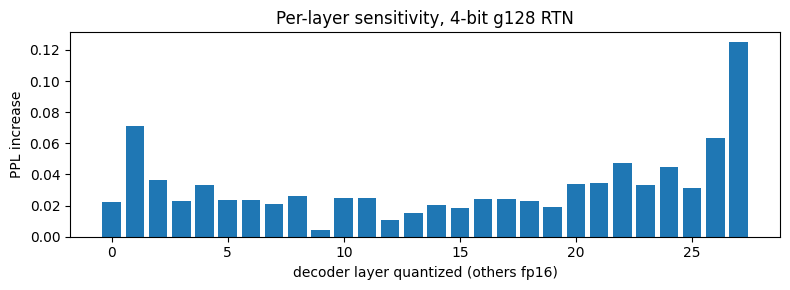

In [16]:
# per-layer sensitivity: 4-bit g128 on one layer at a time, 8 PPL windows each
if RUN_ABLATIONS:
    restore()
    base = wikitext2_ppl(model, tok, max_windows=8)
    sens = []
    for i, layer in enumerate(model.model.layers):
        saved = {n: p.data.clone() for n, p in layer.named_parameters() if p.ndim == 2}
        for n, p in layer.named_parameters():
            if p.ndim == 2:
                p.data = rtn_fake_quant(p.data, 4, 128, False)
        sens.append(wikitext2_ppl(model, tok, max_windows=8) - base)
        for n, p in layer.named_parameters():
            if n in saved:
                p.data = saved[n]
    restore(); free()
    plt.figure(figsize=(8, 3)); plt.bar(range(len(sens)), sens)
    plt.xlabel("decoder layer quantized (others fp16)"); plt.ylabel("PPL increase"); plt.title("Per-layer sensitivity, 4-bit g128 RTN")
    plt.tight_layout(); plt.savefig(f"{OUT}/figures/sensitivity.png", dpi=150); plt.show()

In [17]:
# GPTQ: calibration size, and per-channel
GABL = []
if RUN_GPTQ and RUN_ABLATIONS:
    for n_cal in (16, 64):
        restore()
        ptq.gptq_quantize_model(model, CALIB[:n_cal], GROUP, batch_size=CALIB_BATCH, log=None)
        seed_all(); GABL.append(dict(ablation=f"GPTQ g128, {n_cal} calib windows", ppl=round(wikitext2_ppl(model, tok), 3)))
        print(GABL[-1])
    main = next((r for r in RESULTS if r["method"] == "GPTQ (mine)"), None)
    if main:
        GABL.append(dict(ablation=f"GPTQ g128, {CALIB_N} calib windows (main row)", ppl=main["ppl"]))
    restore()
    ptq.gptq_quantize_model(model, CALIB, -1, batch_size=CALIB_BATCH, log=None)
    seed_all(); GABL.append(dict(ablation="GPTQ per-channel (group = K)", ppl=round(wikitext2_ppl(model, tok), 3)))
    rtn_pc = next((a["ppl"] for a in ABL if a["ablation"] == "RTN 4-bit asym, group=-1"), None)
    if rtn_pc:
        GABL.append(dict(ablation="RTN per-channel (for comparison)", ppl=rtn_pc))
    restore(); free()
pd.DataFrame(GABL)

{'ablation': 'GPTQ g128, 16 calib windows', 'ppl': 10.067}
{'ablation': 'GPTQ g128, 64 calib windows', 'ppl': 9.903}


,ablation,ppl
0,"GPTQ g128, 16 calib windows",10.067
1,"GPTQ g128, 64 calib windows",9.903
2,"GPTQ g128, 128 calib windows (main row)",9.844
3,GPTQ per-channel (group = K),11.781
4,RTN per-channel (for comparison),13.505


## 4. Kernels

`w4a16.py` has three ways to run each format, picked by M (the number of tokens in the call):
- `gemv` for decode-sized M. No tensor cores; each packed int32 is loaded once and its 8 nibbles are multiplied against 8 strided slices of the activation row.
- `dot` for medium M: tiled `tl.dot` on tiles dequantized in registers.
- `dequant` for large M: dequantize the weight to fp16 once with a small Triton kernel and hand the matmul to cuBLAS. At large M the matmul is compute-bound and cuBLAS is hard to beat.

My first version stored packed weights as [N, K/8] and was about 9x slower than fp16 at decode (around 6 GB/s). v2 stores them as [K/8, N] so neighbouring output channels are neighbouring words, adds the gemv path, and pulls scale and zero-point out of the inner loop (Σ a(q−z)s = s·Σaq − s·z·Σa). That made the kernels faster than fp16, but end-to-end decode got slower (0.56x). v3 deals with launch overhead: it caches each autotuned config and launches the kernel directly, fuses the bias, and adds a CUDA-graph decode loop (4e, 4f).

4a checks the packing, 4b checks every path, 4c is the latency sweep, 4d swaps the kernels into the model, 4e looks at launch overhead and 4f measures decode.

In [18]:
importlib.reload(w4a16); importlib.reload(ptq)

# 4a: packing check
Wt = (torch.randn(512, 1024, device="cuda") * 0.02).half()
qw, s, z = w4a16.quantize_pack_int4(Wt, 128)
assert qw.dtype == torch.int32 and qw.shape == (1024 // 8, 512) and s.shape == (1024 // 128, 512)
deq = w4a16.dequant_ref(qw, s, z, 128).float()

# packed weights should match ptq.fake_quant_int4 exactly (both use fp16 scales)
assert torch.equal(deq, ptq.fake_quant_int4(Wt, 128).half().float()), "packing is not lossless"

# section 1 keeps the scale in fp32, so a weight sitting on a rounding tie can land one level away
step = s.float().T.repeat_interleave(128, dim=1)                        # one level, per element
lv = (deq - rtn_fake_quant(Wt, 4, 128, False).float()).abs() / step
print(f"vs section-1 RTN: {100 * (lv > 0.5).float().mean():.3f}% of weights differ, max {lv.max():.2f} level(s)")
assert lv.max() < 1.05 and (lv > 0.5).float().mean() < 1e-3
print("packing OK")

vs section-1 RTN: 0.028% of weights differ, max 1.00 level(s)
packing OK


In [19]:
# 4b: each path against the PyTorch reference, random and real weights, M = 1 / 16 / 512
def _rel(out, ref):
    return ((out.float() - ref).abs().max() / ref.abs().max()).item()

@torch.no_grad()
def check_paths(W, tag, Ms=(1, 16, 512)):
    qw, s, z = w4a16.quantize_pack_int4(W, GROUP)
    q8, s8 = w4a16.quantize_int8_per_channel(W)
    w4ref, w8ref = w4a16.dequant_ref(qw, s, z, GROUP).float(), w4a16.dequant_int8_ref(q8, s8).float()
    out = []
    for M in Ms:
        A = torch.randn(M, W.shape[1], device="cuda", dtype=torch.float16)
        r4, r8 = A.float() @ w4ref.T, A.float() @ w8ref.T
        for path in ("gemv", "dot", "dequant"):
            if path == "gemv" and M > 16:
                continue
            out.append(dict(weights=tag, M=M, path=path,
                            w4_rel_err=_rel(w4a16.w4a16_matmul(A, qw, s, z, GROUP, path=path), r4),
                            w8_rel_err=_rel(w4a16.w8a16_matmul(A, q8, s8, path=path), r8)))
    return out

cfg = model.config
CORR = pd.DataFrame(
    check_paths((torch.randn(cfg.intermediate_size, cfg.hidden_size, device="cuda") * 0.02).half(), "random gate/up")
    + check_paths(ORIG["model.layers.10.mlp.gate_proj.weight"], "real L10 gate_proj")
    + check_paths(ORIG["model.layers.10.mlp.down_proj.weight"], "real L10 down_proj"))
assert (CORR[["w4_rel_err", "w8_rel_err"]] < 2e-3).all().all(), "a kernel path disagrees with the reference"
print("all paths correct (max rel err w4 %.1e, w8 %.1e)" % (CORR.w4_rel_err.max(), CORR.w8_rel_err.max()))
CORR

all paths correct (max rel err w4 6.0e-04, w8 5.1e-04)


,weights,M,path,w4_rel_err,w8_rel_err
0,random gate/up,1,gemv,0.000386,0.000352
1,random gate/up,1,dot,0.000386,0.000352
2,random gate/up,1,dequant,0.000294,0.000280
3,random gate/up,16,gemv,0.000375,0.000386
4,random gate/up,16,dot,0.000375,0.000386
5,random gate/up,16,dequant,0.000276,0.000274
6,random gate/up,512,dot,0.000518,0.000450
7,random gate/up,512,dequant,0.000458,0.000450
8,real L10 gate_proj,1,gemv,0.000343,0.000356
9,real L10 gate_proj,1,dot,0.000343,0.000356


### 4c. Latency sweep

Every path on the real layer shapes of Qwen2.5-1.5B plus three 7B-sized shapes, for M from 1 to 1024. Each new shape/path/M bucket autotunes the first time, so this takes about 10 minutes.

GB/s is the minimum number of bytes the method has to move divided by the time; the T4 peaks around 320. TFLOPS is 2·M·N·K / time, with a tensor-core peak around 65.

In [20]:
cfg = model.config
KV_DIM = cfg.num_key_value_heads * (cfg.hidden_size // cfg.num_attention_heads)
SHAPES = {   # name: (N, K, occurrences per decoder layer; 0 = generic shape, not in this model)
    "qwen gate/up": (cfg.intermediate_size, cfg.hidden_size, 2),
    "qwen down":    (cfg.hidden_size, cfg.intermediate_size, 1),
    "qwen q/o":     (cfg.hidden_size, cfg.hidden_size, 2),
    "qwen k/v":     (KV_DIM, cfg.hidden_size, 2),
    "4096x4096":    (4096, 4096, 0),
    "11008x4096":   (11008, 4096, 0),
    "4096x11008":   (4096, 11008, 0),
}
MS = (1, 4, 16, 64, 128, 512, 1024)
GEMV_MS = (1, 4, 16)

def min_bytes(kind, M, N, K, g=GROUP):
    act = (M * K + M * N) * 2
    w = {"fp16": N * K * 2, "w8": N * K + N * 2, "w4": N * K // 2 + 2 * N * (K // g) * 2}[kind]
    return w + act

def bench_ms(fn):
    return triton.testing.do_bench(fn, warmup=25, rep=100, return_mode="median")

def run_sweep(shapes=SHAPES, ms=MS):
    rows, errors = [], []
    for lname, (N, K, _) in shapes.items():
        torch.manual_seed(SEED)
        W = (torch.randn(N, K, device="cuda") * 0.02).half()
        qw, s, z = w4a16.quantize_pack_int4(W, GROUP)
        q8, s8 = w4a16.quantize_int8_per_channel(W)
        for M in ms:
            A = torch.randn(M, K, device="cuda", dtype=torch.float16)
            impls = [("fp16 cuBLAS", "fp16", partial(torch.matmul, A, W.T))]
            for p in ("gemv", "dot", "dequant"):
                if p == "gemv" and M not in GEMV_MS:
                    continue
                impls.append((f"w8 {p}", "w8", partial(w4a16.w8a16_matmul, A, q8, s8, path=p)))
                impls.append((f"w4 {p}", "w4", partial(w4a16.w4a16_matmul, A, qw, s, z, GROUP, path=p)))
            for name, kind, fn in impls:
                try:
                    fn(); torch.cuda.synchronize()                 # warm-up + autotune
                    ms_ = bench_ms(fn)
                except Exception as e:                             # log it and keep going
                    errors.append((lname, M, name, repr(e)[:200])); continue
                rows.append(dict(shape=lname, N=N, K=K, M=M, impl=name, kind=kind, ms=ms_,
                                 GBps=min_bytes(kind, M, N, K) / (ms_ * 1e-3) / 1e9,
                                 TFLOPS=2 * M * N * K / (ms_ * 1e-3) / 1e12))
        print(f"{lname}: done"); del W, qw, s, z, q8, s8; free()
    for e in errors:
        print("ERROR", e)
    return pd.DataFrame(rows)

if RUN_KERNEL_SWEEP:
    BENCH = run_sweep()
    BENCH.to_csv(f"{OUT}/kernel_bench.csv", index=False)
elif os.path.exists(f"{OUT}/kernel_bench.csv"):
    BENCH = pd.read_csv(f"{OUT}/kernel_bench.csv")

qwen gate/up: done
qwen down: done
qwen q/o: done
qwen k/v: done
4096x4096: done
11008x4096: done
4096x11008: done


In [21]:
def analyze_sweep(bench, shapes):
    """Latency table, best path per format, speedups vs fp16, and the M crossovers for path dispatch."""
    lat = bench.pivot_table(index=["shape", "M"], columns="impl", values="ms")
    w4c = [c for c in lat.columns if c.startswith("w4 ")]
    w8c = [c for c in lat.columns if c.startswith("w8 ")]
    summ = pd.DataFrame({"fp16_ms": lat["fp16 cuBLAS"],
                         "best_w4": lat[w4c].idxmin(axis=1).str[3:], "w4_ms": lat[w4c].min(axis=1),
                         "best_w8": lat[w8c].idxmin(axis=1).str[3:], "w8_ms": lat[w8c].min(axis=1)})
    summ["w4_speedup"] = summ.fp16_ms / summ.w4_ms
    summ["w8_speedup"] = summ.fp16_ms / summ.w8_ms
    gb = bench[bench.impl.str.startswith("w4 ")].groupby(["shape", "M"])["GBps"].max()
    summ["w4_best_GBps"] = gb

    # crossovers on the real model: time per decoder layer = sum over its linears
    counts = {n: c for n, (_, _, c) in shapes.items() if c > 0}
    real = bench[bench["shape"].isin(counts) & bench.impl.str.startswith("w4 ")].copy()
    real["layer_ms"] = real["ms"] * real["shape"].map(counts)
    per_m = real.groupby(["M", "impl"])["layer_ms"].sum(min_count=len(counts)).unstack()
    best = per_m.idxmin(axis=1).str[3:]
    gemv_max = 0
    for M in sorted(best.index):
        if best[M] != "gemv":
            break
        gemv_max = M
    non_deq = [M for M in sorted(best.index) if best[M] != "dequant"]
    dot_max = max([gemv_max] + non_deq)
    return lat, summ, per_m, best, gemv_max, dot_max

LAT, SUMMARY, PER_LAYER, BEST_PATH, GEMV_MAX, DOT_MAX = analyze_sweep(BENCH, SHAPES)
w4a16.GEMV_MAX_M, w4a16.DOT_MAX_M = GEMV_MAX, DOT_MAX
print("fastest W4 path per M (whole decoder layer):", BEST_PATH.to_dict())
print(f"-> dispatch set to: gemv for M <= {GEMV_MAX}, dot for M <= {DOT_MAX}, dequant+cuBLAS above")
SUMMARY.round(3)

fastest W4 path per M (whole decoder layer): {1: 'gemv', 4: 'gemv', 16: 'dequant', 64: 'dequant', 128: 'dequant', 512: 'dequant', 1024: 'dequant'}
-> dispatch set to: gemv for M <= 4, dot for M <= 4, dequant+cuBLAS above


fp16_ms  best_w4  w4_ms  best_w8  w8_ms  w4_speedup  \
shape        M                                                           
11008x4096   1       0.366     gemv  0.115     gemv  0.203       3.185   
             4       0.383     gemv  0.290     gemv  0.342       1.320   
             16      0.389  dequant  0.953     gemv  1.234       0.408   
             64      0.531  dequant  0.966  dequant  2.003       0.550   
             128     0.557  dequant  1.057  dequant  2.216       0.527   
             512     2.341  dequant  2.559  dequant  3.489       0.915   
             1024    4.377  dequant  4.650  dequant  5.878       0.941   
4096x11008   1       0.387     gemv  0.133     gemv  0.227       2.920   
             4       0.413     gemv  0.318     gemv  0.368       1.298   
             16      0.418  dequant  0.938      dot  1.122       0.446   
             64      0.487  dequant  0.920  dequant  1.877       0.529   
             128     0.551  dequant  1.092  dequant  2.141       0.505   
             512     2.621  dequant  2.858  dequant  3.728       0.917   
             1024    7.188  dequant  5.428  dequant  6.741       1.324   
4096x4096    1       0.143     gemv  0.057     gemv  0.090       2.495   
             4       0.162     gemv  0.111     gemv  0.116       1.460   
             16      0.166  dequant  0.367      dot  0.397       0.453   
             64      0.184  dequant  0.349  dequant  0.664       0.529   
             128     0.190  dequant  0.366  dequant  0.723       0.519   
             512     0.666  dequant  0.829  dequant  1.343       0.804   
             1024    1.616  dequant  1.563  dequant  2.006       1.034   
qwen down    1       0.126     gemv  0.073     gemv  0.111       1.722   
             4       0.132     gemv  0.114     gemv  0.129       1.158   
             16      0.133  dequant  0.299     gemv  0.364       0.445   
             64      0.180  dequant  0.309  dequant  0.565       0.584   
             128     0.194  dequant  0.318  dequant  0.614       0.609   
             512     0.535  dequant  0.622  dequant  0.965       0.860   
             1024    1.420  dequant  1.287  dequant  1.636       1.104   
qwen gate/up 1       0.129     gemv  0.047     gemv  0.073       2.744   
             4       0.131     gemv  0.080     gemv  0.092       1.642   
             16      0.160  dequant  0.293     gemv  0.306       0.546   
             64      0.163  dequant  0.286  dequant  0.564       0.568   
             128     0.170  dequant  0.312  dequant  0.606       0.546   
             512     0.504  dequant  0.626  dequant  0.971       0.805   
             1024    1.032  dequant  1.298  dequant  1.720       0.795   
qwen k/v     1       0.010     gemv  0.014     gemv  0.019       0.704   
             4       0.014     gemv  0.016     gemv  0.020       0.893   
             16      0.014  dequant  0.016     gemv  0.023       0.844   
             64      0.016  dequant  0.018  dequant  0.031       0.883   
             128     0.022  dequant  0.023  dequant  0.037       0.964   
             512     0.031  dequant  0.035  dequant  0.048       0.890   
             1024    0.043  dequant  0.045  dequant  0.060       0.960   
qwen q/o     1       0.034     gemv  0.016     gemv  0.024       2.087   
             4       0.033     gemv  0.023     gemv  0.027       1.449   
             16      0.033  dequant  0.052     gemv  0.059       0.635   
             64      0.052  dequant  0.059  dequant  0.107       0.874   
             128     0.051  dequant  0.063  dequant  0.111       0.810   
             512     0.089  dequant  0.116  dequant  0.176       0.764   
             1024    0.156  dequant  0.182  dequant  0.254       0.854   

                   w8_speedup  w4_best_GBps  
shape        M                               
11008x4096   1          1.804       208.597  
             4          1.118        82.932  
             16         0.315        25.636  
             6

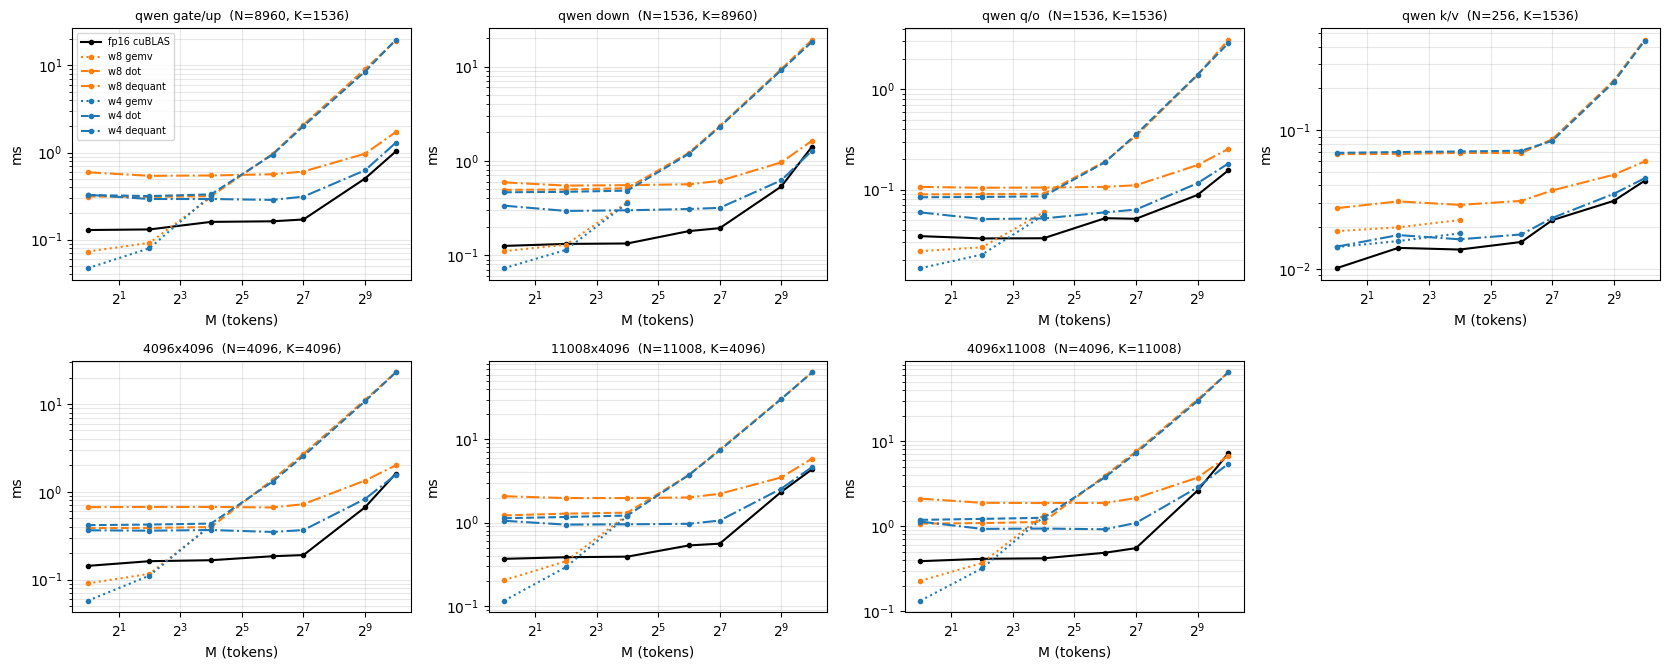

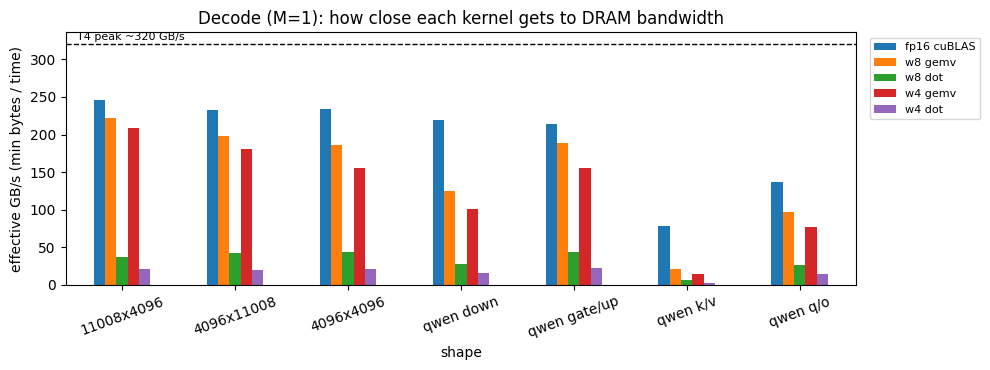

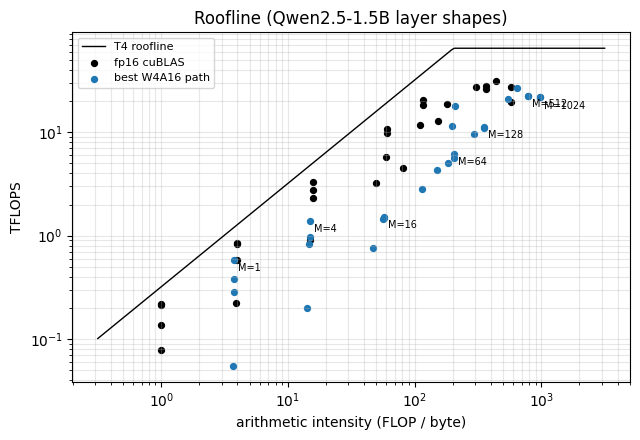

In [22]:
def plot_latency(bench, shapes, path=f"{OUT}/figures/kernel_latency.png"):
    names = list(shapes)
    cols = 4
    rows_ = math.ceil(len(names) / cols)
    fig, axes = plt.subplots(rows_, cols, figsize=(4.2 * cols, 3.4 * rows_), squeeze=False)
    style = {"fp16 cuBLAS": ("k", "-"), "w8 gemv": ("tab:orange", ":"), "w8 dot": ("tab:orange", "--"), "w8 dequant": ("tab:orange", "-."),
             "w4 gemv": ("tab:blue", ":"), "w4 dot": ("tab:blue", "--"), "w4 dequant": ("tab:blue", "-.")}
    for ax, name in zip(axes.flat, names):
        d = bench[bench["shape"] == name]
        for impl, (c, ls) in style.items():
            dd = d[d.impl == impl].sort_values("M")
            if len(dd):
                ax.plot(dd.M, dd.ms, color=c, ls=ls, marker="o", ms=3, label=impl)
        N, K, _ = shapes[name]
        ax.set_xscale("log", base=2); ax.set_yscale("log")
        ax.set_title(f"{name}  (N={N}, K={K})", fontsize=9); ax.set_xlabel("M (tokens)"); ax.set_ylabel("ms")
        ax.grid(alpha=0.3, which="both")
    for ax in list(axes.flat)[len(names):]:
        ax.axis("off")
    axes.flat[0].legend(fontsize=7)
    plt.tight_layout(); plt.savefig(path, dpi=150); plt.show()

def plot_decode_bandwidth(bench, peak=T4_PEAK_GBPS, path=f"{OUT}/figures/decode_bandwidth.png"):
    d = bench[bench.M == 1]
    piv = d.pivot_table(index="shape", columns="impl", values="GBps")
    keep = [c for c in ["fp16 cuBLAS", "w8 gemv", "w8 dot", "w4 gemv", "w4 dot"] if c in piv.columns]
    ax = piv[keep].plot.bar(figsize=(10, 3.8), rot=20)
    ax.axhline(peak, color="k", ls="--", lw=1); ax.text(-0.4, peak * 1.02, f"T4 peak ~{peak} GB/s", fontsize=8)
    ax.set_ylabel("effective GB/s (min bytes / time)"); ax.set_title("Decode (M=1): how close each kernel gets to DRAM bandwidth")
    ax.legend(fontsize=8, bbox_to_anchor=(1.01, 1), loc="upper left")
    plt.tight_layout(); plt.savefig(path, dpi=150); plt.show()

def plot_roofline(bench, shapes, peak_gbps=T4_PEAK_GBPS, peak_tflops=T4_PEAK_TFLOPS, path=f"{OUT}/figures/roofline.png"):
    real = [n for n, (_, _, c) in shapes.items() if c > 0]
    d = bench[bench["shape"].isin(real)].copy()
    d["AI"] = 2 * d.M * d.N * d.K / d.apply(lambda r: min_bytes(r.kind, r.M, r.N, r.K), axis=1)
    fp = d[d.impl == "fp16 cuBLAS"]
    w4 = d[d.kind == "w4"].sort_values("ms").groupby(["shape", "M"]).head(1)
    x = np.logspace(-0.5, 3.5, 200)
    plt.figure(figsize=(6.5, 4.5))
    plt.plot(x, np.minimum(peak_tflops, peak_gbps * x / 1000), "k-", lw=1, label="T4 roofline")
    plt.scatter(fp.AI, fp.TFLOPS, s=18, c="k", label="fp16 cuBLAS")
    plt.scatter(w4.AI, w4.TFLOPS, s=18, c="tab:blue", label="best W4A16 path")
    for _, r in w4[w4["shape"] == real[0]].iterrows():
        plt.annotate(f"M={r.M}", (r.AI, r.TFLOPS), fontsize=7, xytext=(3, -8), textcoords="offset points")
    plt.xscale("log"); plt.yscale("log"); plt.xlabel("arithmetic intensity (FLOP / byte)"); plt.ylabel("TFLOPS")
    plt.title("Roofline (Qwen2.5-1.5B layer shapes)"); plt.legend(fontsize=8); plt.grid(alpha=0.3, which="both")
    plt.tight_layout(); plt.savefig(path, dpi=150); plt.show()

plot_latency(BENCH, SHAPES)
plot_decode_bandwidth(BENCH)
plot_roofline(BENCH, SHAPES)

### 4d. Swapping the kernels into the model

For each variant I first compute the perplexity of the fake-quant model with exactly the same integer weights, then replace every decoder linear with `W8A16Linear` or `W4A16Linear`, run the full evaluation, and swap back. If the two perplexities match, the packing and kernels are right end to end. `lm_head` stays fp16 in every row.

In [23]:
@torch.no_grad()
def apply_packed_fake(res, g=GROUP):
    """Write the fake-quant twin of packed results into the model (dequant, and / in_scale for AWQ)."""
    for name, r in res.items():
        w = w4a16.dequant_ref(*[t.cuda() for t in r["packed"]], g).float()
        if r["in_scale"] is not None:
            w = w / r["in_scale"].cuda().float()
        model.get_submodule(name).weight.data.copy_(w.half())

def find_row(label, bits, grp):
    return next((r for r in RESULTS if r["method"] == label and r["bits"] == bits and str(r["group"]) == str(grp)), None)

def run_kernel_variant(label, res=None, w8=False):
    bits, grp = (8, "-") if w8 else (4, GROUP)
    row = find_row(label, bits, grp)
    if row is not None and row.get("kernel_version") == w4a16.KERNEL_VERSION:
        print("skip (done):", label); return
    restore()
    if w8:
        ptq.fake_quant_int8_per_channel_model(model)
    else:
        apply_packed_fake(res)
    seed_all(); ppl_fake = wikitext2_ppl(model, tok)
    restore(); free()
    originals = ptq.swap_w8(model) if w8 else ptq.swap_w4(model, res, GROUP)
    try:
        row = evaluate(label, model, tok, bits=bits, group=grp,
                       extra=dict(ppl_fake_quant=round(ppl_fake, 3), kernel_version=w4a16.KERNEL_VERSION))
        print(f"PPL parity  fake-quant {ppl_fake:.3f}  vs  kernel {row['ppl']:.3f}")
    finally:
        ptq.unswap(model, originals); del originals; free(); restore()

run_kernel_variant("W8A16 Triton (RTN per-channel)", w8=True)

restore(); RTN_PACKED = ptq.rtn_quantize_model(model, GROUP); restore()
run_kernel_variant("W4A16 Triton (RTN g128)", RTN_PACKED)
if get_packed("gptq") is not None:
    run_kernel_variant("W4A16 Triton (GPTQ g128)", get_packed("gptq"))
if get_packed("awq") is not None:
    run_kernel_variant("W4A16 Triton (AWQ g128)", get_packed("awq"))
results_df()

Running loglikelihood requests: 100%|██████████| 7997/7997 [01:54<00:00, 69.78it/s] 


{'method': 'W8A16 Triton (RTN per-channel)', 'bits': 8, 'group': '-', 'ppl': 9.279, 'weights_gb': 1.779, 'est_peak_gb': 4.27, 'arc_easy': 0.75, 'arc_easy_se': 0.0137, 'hellaswag_norm': 0.583, 'hellaswag_norm_se': 0.0156, 'decode_tok_s': 19.2, 'ppl_fake_quant': 9.279, 'kernel_version': 3}
PPL parity  fake-quant 9.279  vs  kernel 9.279


Running loglikelihood requests: 100%|██████████| 7997/7997 [01:30<00:00, 88.46it/s] 


{'method': 'W4A16 Triton (RTN g128)', 'bits': 4, 'group': 128, 'ppl': 10.357, 'weights_gb': 1.163, 'est_peak_gb': 3.65, 'arc_easy': 0.706, 'arc_easy_se': 0.0144, 'hellaswag_norm': 0.571, 'hellaswag_norm_se': 0.0157, 'decode_tok_s': 17.6, 'ppl_fake_quant': 10.357, 'kernel_version': 3}
PPL parity  fake-quant 10.357  vs  kernel 10.357


Running loglikelihood requests: 100%|██████████| 7997/7997 [01:30<00:00, 88.78it/s] 


{'method': 'W4A16 Triton (GPTQ g128)', 'bits': 4, 'group': 128, 'ppl': 9.844, 'weights_gb': 1.163, 'est_peak_gb': 3.65, 'arc_easy': 0.751, 'arc_easy_se': 0.0137, 'hellaswag_norm': 0.579, 'hellaswag_norm_se': 0.0156, 'decode_tok_s': 17.9, 'ppl_fake_quant': 9.844, 'kernel_version': 3}
PPL parity  fake-quant 9.844  vs  kernel 9.844


Running loglikelihood requests: 100%|██████████| 7997/7997 [01:34<00:00, 84.84it/s]


{'method': 'W4A16 Triton (AWQ g128)', 'bits': 4, 'group': 128, 'ppl': 10.017, 'weights_gb': 1.164, 'est_peak_gb': 3.65, 'arc_easy': 0.73, 'arc_easy_se': 0.014, 'hellaswag_norm': 0.577, 'hellaswag_norm_se': 0.0156, 'decode_tok_s': 17.0, 'ppl_fake_quant': 10.017, 'kernel_version': 3}
PPL parity  fake-quant 10.017  vs  kernel 10.017


,method,bits,group,ppl,weights_gb,est_peak_gb,arc_easy,arc_easy_se,hellaswag_norm,hellaswag_norm_se,decode_tok_s,quant_time_s,ppl_fake_quant,kernel_version
0,FP16,16,-,9.265,3.087,5.58,0.751,0.0137,0.583,0.0156,24.6,NaN,NaN,NaN
1,RTN-asym (mine),8,128,9.268,1.818,4.31,0.743,0.0138,0.582,0.0156,NaN,NaN,NaN,NaN
2,RTN-asym (mine),4,128,10.360,1.163,3.65,0.705,0.0144,0.572,0.0157,NaN,NaN,NaN,NaN
3,RTN-sym (mine),4,128,10.851,1.143,3.63,0.719,0.0142,0.576,0.0156,NaN,NaN,NaN,NaN
4,RTN-asym (mine),4,-1,13.505,1.125,3.61,0.693,0.0146,0.567,0.0157,NaN,NaN,NaN,NaN
5,GPTQ (mine),4,128,9.844,1.163,3.65,0.750,0.0137,0.578,0.0156,NaN,496.0,NaN,NaN
6,AWQ (mine),4,128,10.017,1.163,3.65,0.729,0.0141,0.576,0.0156,NaN,310.0,NaN,NaN
7,bnb NF4,4,64,9.928,1.122,3.61,0.716,0.0143,0.588,0.0156,18.5,NaN,NaN,NaN
8,bnb INT8,8,-,9.318,1.777,4.27,0.745,0.0138,0.583,0.0156,6.3,NaN,NaN,NaN
9,W8A16 Triton (RTN per-channel),8,-,9.279,1.779,4.27,0.750,0.0137,0.583,0.0156,19.2,NaN,9.279,3.0


### 4e. Launch overhead

The kernels were faster than fp16 but decode wasn't, so here I time one layer (gate_proj, M=1) several ways:
- cpu_us: how long Python takes to queue one call (the GPU runs asynchronously)
- wall_us: time per call when calls run back to back
- gpu_us: kernel time alone, from `do_bench`

If cpu_us is bigger than gpu_us, the GPU finishes early and waits for the next launch, so a faster kernel doesn't help. The last two rows put 100 calls into one CUDA graph, which takes Python out of the loop.

In [24]:
import time
restore()
lin = model.model.layers[10].mlp.gate_proj                      # plain fp16 nn.Linear (cuBLAS)
K_ = lin.in_features
mod4 = w4a16.W4A16Linear(lin, GROUP)                             # same layer, W4A16 kernel
x = torch.randn(1, 1, K_, device="cuda", dtype=torch.float16)
A = x.view(1, K_)
mod4(x); torch.cuda.synchronize()                                # autotune once
qw, s, z = mod4.qweight, mod4.scales, mod4.zeros

def via_autotuner():                                             # how v2 launched: every call goes through triton.autotune
    w4a16.FAST_LAUNCH = False
    try:
        return w4a16.w4a16_matmul(A, qw, s, z, GROUP, path="gemv")
    finally:
        w4a16.FAST_LAUNCH = True

def graph_per_call(fn, calls=100, replays=20):
    fn(); torch.cuda.synchronize()
    g = torch.cuda.CUDAGraph()
    with torch.cuda.graph(g):
        for _ in range(calls):
            fn()
    g.replay(); torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(replays):
        g.replay()
    torch.cuda.synchronize()
    return (time.perf_counter() - t0) / (calls * replays) * 1e6

CALLS = {
    "fp16 nn.Linear (cuBLAS)":            lambda: lin(x),
    "W4 kernel via autotuner (v2 launch)": via_autotuner,
    "W4 kernel, cached config (v3)":       lambda: w4a16.w4a16_matmul(A, qw, s, z, GROUP, path="gemv"),
    "W4A16Linear module (v3)":             lambda: mod4(x),
}
rows_ = []
for name, fn in CALLS.items():
    cpu_us, wall_us = db.per_call_overhead(fn)
    gpu_us = triton.testing.do_bench(fn, warmup=25, rep=100, return_mode="median") * 1e3
    rows_.append(dict(call=name, cpu_us=cpu_us, wall_us=wall_us, gpu_us=gpu_us, launch_bound=cpu_us > gpu_us))
for name, fn in [("fp16 nn.Linear in a CUDA graph", lambda: lin(x)), ("W4A16Linear in a CUDA graph", lambda: mod4(x))]:
    rows_.append(dict(call=name, cpu_us=float("nan"), wall_us=graph_per_call(fn), gpu_us=float("nan"), launch_bound=False))
OVERHEAD = pd.DataFrame(rows_).round(1)

n_lin = 7 * model.config.num_hidden_layers
w = OVERHEAD.set_index("call")
print(f"{n_lin} linear calls per token. Python enqueue cost per token for the linears alone: "
      f"fp16 ~{n_lin * w.loc['fp16 nn.Linear (cuBLAS)', 'cpu_us'] / 1e3:.1f} ms, "
      f"W4 module ~{n_lin * w.loc['W4A16Linear module (v3)', 'cpu_us'] / 1e3:.1f} ms")
OVERHEAD.to_csv(f"{OUT}/launch_overhead.csv", index=False)
del mod4; free()
OVERHEAD

196 linear calls per token. Python enqueue cost per token for the linears alone: fp16 ~6.8 ms, W4 module ~13.7 ms


,call,cpu_us,wall_us,gpu_us,launch_bound
0,fp16 nn.Linear (cuBLAS),34.9,118.3,131.1,False
1,W4 kernel via autotuner (v2 launch),78.7,78.8,47.1,True
2,"W4 kernel, cached config (v3)",49.6,49.8,47.1,True
3,W4A16Linear module (v3),69.9,70.0,46.9,True
4,fp16 nn.Linear in a CUDA graph,NaN,167.4,NaN,False
5,W4A16Linear in a CUDA graph,NaN,64.1,NaN,False


### 4f. Decode: generate vs static cache vs CUDA graph

Same prompt, greedy, 128 new tokens (`decode_bench.py`):
- generate: HF default with the dynamic cache
- static eager: my loop over a static KV cache, one Python forward per token
- CUDA graph: the same step captured once and replayed

All three are greedy, so they should give the same tokens. `match_*` is the fraction of tokens that agree with `generate` before the first difference.

In [25]:
DECODE_PROMPT = torch.randint(1000, 30000, (1, DECODE_PROMPT_LEN), generator=torch.Generator().manual_seed(SEED)).cuda()
PAD = tok.pad_token_id if tok.pad_token_id is not None else tok.eos_token_id
VARIANTS = [("FP16", 16, "-", None), ("W8A16 Triton (RTN per-channel)", 8, "-", "w8"),
            ("W4A16 Triton (RTN g128)", 4, GROUP, "rtn"), ("W4A16 Triton (GPTQ g128)", 4, GROUP, "gptq"),
            ("W4A16 Triton (AWQ g128)", 4, GROUP, "awq")]

for label, bits, grp, kind in VARIANTS:
    row = find_row(label, bits, grp)
    if row is None:
        print("no row yet, skipping:", label); continue
    if RESUME and row.get("decode_version") == w4a16.KERNEL_VERSION:   # re-measured whenever kernels change
        print("skip (done):", label); continue
    restore(); free()
    originals = None
    if kind == "w8":
        originals = ptq.swap_w8(model)
    elif kind is not None:
        res = RTN_PACKED if kind == "rtn" else get_packed(kind)
        if res is None:
            print("no packed weights, skipping:", label); continue
        originals = ptq.swap_w4(model, res, GROUP)
    try:
        rep_ = db.decode_report(model, DECODE_PROMPT, DECODE_NEW_TOKENS, PAD)
    finally:
        if originals is not None:
            ptq.unswap(model, originals)
        restore(); free()
    row.update({k: (round(v, 1) if k.startswith("tok_s") else (round(v, 3) if isinstance(v, float) else v)) for k, v in rep_.items()})
    row["decode_version"] = w4a16.KERNEL_VERSION
    json.dump(RESULTS, open(RESULTS_JSON, "w"), indent=1)
    print(label, rep_)

DEC = pd.DataFrame([{k: r.get(k) for k in ("method", "tok_s_generate", "tok_s_static_eager", "tok_s_cuda_graph",
                                            "match_static_eager", "match_cuda_graph")} for r in RESULTS if "tok_s_generate" in r])
DEC

FP16 {'tok_s_generate': 24.8346051522151, 'tok_s_static_eager': 27.610290092402717, 'match_static_eager': 1.0, 'tok_s_cuda_graph': 50.02473595177583, 'match_cuda_graph': 1.0}
W8A16 Triton (RTN per-channel) {'tok_s_generate': 18.286522482043743, 'tok_s_static_eager': 20.634584475076203, 'match_static_eager': 1.0, 'tok_s_cuda_graph': 64.1461480299452, 'match_cuda_graph': 1.0}
W4A16 Triton (RTN g128) {'tok_s_generate': 18.014520249143086, 'tok_s_static_eager': 20.239029055854758, 'match_static_eager': 1.0, 'tok_s_cuda_graph': 77.41788326574597, 'match_cuda_graph': 1.0}
W4A16 Triton (GPTQ g128) {'tok_s_generate': 17.242965824721608, 'tok_s_static_eager': 19.526651300047643, 'match_static_eager': 1.0, 'tok_s_cuda_graph': 77.04450307318257, 'match_cuda_graph': 1.0}
W4A16 Triton (AWQ g128) {'tok_s_generate': 16.82867758250918, 'tok_s_static_eager': 18.67697424855203, 'match_static_eager': 1.0, 'tok_s_cuda_graph': 75.53649129766714, 'match_cuda_graph': 1.0}


,method,tok_s_generate,tok_s_static_eager,tok_s_cuda_graph,match_static_eager,match_cuda_graph
0,FP16,24.8,27.6,50.0,1.0,1.0
1,W8A16 Triton (RTN per-channel),18.3,20.6,64.1,1.0,1.0
2,W4A16 Triton (RTN g128),18.0,20.2,77.4,1.0,1.0
3,W4A16 Triton (GPTQ g128),17.2,19.5,77.0,1.0,1.0
4,W4A16 Triton (AWQ g128),16.8,18.7,75.5,1.0,1.0


## 5. Results

Weights GB is measured for the bitsandbytes and Triton rows and is the packed size for fake-quant rows. Accuracy is value ± standard error. The tables are also written to `OUT` as markdown/CSV, and the plots go to `OUT/figures`.

In [26]:
def pm(v, se):
    return "" if v is None or (isinstance(v, float) and math.isnan(v)) else (f"{v:.3f} ± {se:.3f}" if se == se and se is not None else f"{v:.3f}")

def results_table(df):
    t = pd.DataFrame({
        "method": df.method, "bits": df.bits, "group": df.group, "PPL": df.ppl,
        "ARC-E": [pm(v, s) for v, s in zip(df.get("arc_easy", [None] * len(df)), df.get("arc_easy_se", [None] * len(df)))],
        "HellaSwag (norm)": [pm(v, s) for v, s in zip(df.get("hellaswag_norm", [None] * len(df)), df.get("hellaswag_norm_se", [None] * len(df)))],
        "weights GB": df.weights_gb, "est. peak GB": df.get("est_peak_gb"), "decode tok/s (generate)": df.decode_tok_s,
    })
    if "tok_s_cuda_graph" in df:
        t["decode tok/s (CUDA graph)"] = df.tok_s_cuda_graph
    if "ppl_fake_quant" in df:
        t["PPL (fake-quant twin)"] = df.ppl_fake_quant
    return t

def kernel_summary_md(summ):
    s = summ.reset_index()
    s = s[s.M.isin([1, 16, 512])]
    cols = ["shape", "M", "fp16_ms", "best_w4", "w4_ms", "w4_speedup", "w4_best_GBps", "best_w8", "w8_ms", "w8_speedup"]
    return s[cols].round(3).to_markdown(index=False)

def headline(df, summ, shapes):
    lines = []
    fp = df[df.method == "FP16"].iloc[0]
    kern = df[df.method.str.startswith("W4A16 Triton")].dropna(subset=["decode_tok_s"])
    ok = lambda v: v is not None and v == v                     # not None, not NaN
    if len(kern) and "tok_s_cuda_graph" in df and ok(fp.get("tok_s_cuda_graph")) and ok(kern.sort_values("ppl").iloc[0].get("tok_s_cuda_graph")):
        b = kern.sort_values("ppl").iloc[0]
        lines.append(f"- {b.method}, decode with CUDA graphs: {b.tok_s_cuda_graph:.1f} tok/s vs FP16 {fp.tok_s_cuda_graph:.1f} tok/s "
                     f"({b.tok_s_cuda_graph / fp.tok_s_cuda_graph:.2f}x); with HF generate: {b.decode_tok_s:.1f} vs {fp.decode_tok_s:.1f} tok/s.")
    if len(kern):
        b = kern.sort_values("ppl").iloc[0]
        lines.append(f"- {b.method}: decode {b.decode_tok_s:.1f} tok/s vs FP16 {fp.decode_tok_s:.1f} tok/s "
                     f"({b.decode_tok_s / fp.decode_tok_s:.2f}x), WikiText-2 PPL {b.ppl:.2f} vs {fp.ppl:.2f} (+{b.ppl - fp.ppl:.2f}), "
                     f"weights {b.weights_gb:.2f} GB vs {fp.weights_gb:.2f} GB ({fp.weights_gb / b.weights_gb:.1f}x smaller).")
    for name in [n for n, (_, _, c) in shapes.items() if c > 0][:2]:
        if (name, 1) in summ.index:
            r = summ.loc[(name, 1)]
            lines.append(f"- {name} layer at M=1: best W4A16 path `{r.best_w4}` {r.w4_ms * 1000:.1f} µs vs fp16 {r.fp16_ms * 1000:.1f} µs "
                         f"({r.w4_speedup:.2f}x), {r.w4_best_GBps:.0f} GB/s of ~{T4_PEAK_GBPS}.")
        if (name, 512) in summ.index:
            r = summ.loc[(name, 512)]
            lines.append(f"- {name} layer at M=512: best W4A16 path `{r.best_w4}` {r.w4_speedup:.2f}x of fp16 (compute-bound regime).")
    return "\n".join(lines)

df = results_df()
TABLE = results_table(df)
open(f"{OUT}/results_table.md", "w").write(TABLE.to_markdown(index=False))
open(f"{OUT}/kernel_summary.md", "w").write(kernel_summary_md(SUMMARY))
HEADLINE = headline(df, SUMMARY, SHAPES)
open(f"{OUT}/headline.md", "w").write(HEADLINE)
print(TABLE.to_markdown(index=False)); print(); print(HEADLINE)

| method                         |   bits | group   |    PPL | ARC-E         | HellaSwag (norm)   |   weights GB |   est. peak GB |   decode tok/s (generate) |   decode tok/s (CUDA graph) |   PPL (fake-quant twin) |
|:-------------------------------|-------:|:--------|-------:|:--------------|:-------------------|-------------:|---------------:|--------------------------:|----------------------------:|------------------------:|
| FP16                           |     16 | -       |  9.265 | 0.751 ± 0.014 | 0.583 ± 0.016      |        3.087 |           5.58 |                      24.6 |                        50   |                 nan     |
| RTN-asym (mine)                |      8 | 128     |  9.268 | 0.743 ± 0.014 | 0.582 ± 0.016      |        1.818 |           4.31 |                     nan   |                       nan   |                 nan     |
| RTN-asym (mine)                |      4 | 128     | 10.36  | 0.705 ± 0.014 | 0.572 ± 0.016      |        1.163 |           3.65 |     

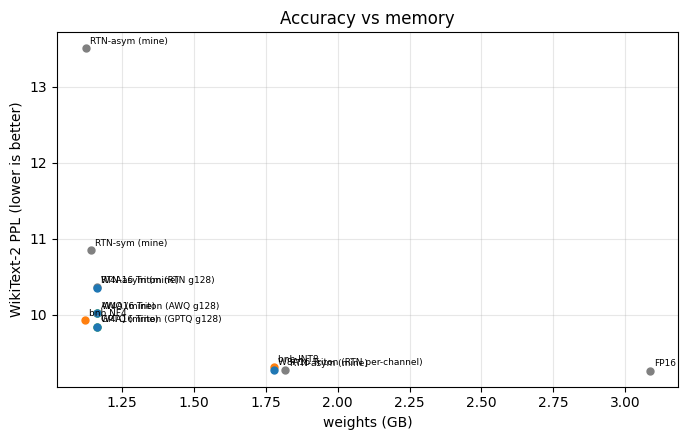

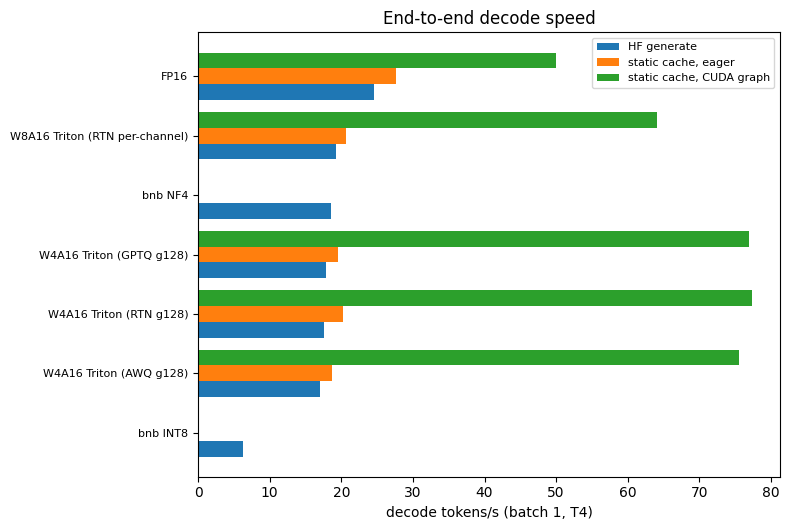

In [27]:
def plot_quality_vs_memory(df, path=f"{OUT}/figures/ppl_vs_memory.png"):
    d = df.dropna(subset=["ppl", "weights_gb"])
    plt.figure(figsize=(7, 4.5))
    for _, r in d.iterrows():
        c = "tab:blue" if "Triton" in r.method else ("tab:green" if r.method in ("GPTQ (mine)", "AWQ (mine)") else ("tab:orange" if "bnb" in r.method else "gray"))
        plt.scatter(r.weights_gb, r.ppl, c=c, s=25)
        plt.annotate(r.method, (r.weights_gb, r.ppl), fontsize=6.5, xytext=(3, 3), textcoords="offset points")
    plt.xlabel("weights (GB)"); plt.ylabel("WikiText-2 PPL (lower is better)"); plt.title("Accuracy vs memory")
    plt.grid(alpha=0.3); plt.tight_layout(); plt.savefig(path, dpi=150); plt.show()

def plot_decode(df, path=f"{OUT}/figures/decode_tok_s.png"):
    d = df.dropna(subset=["decode_tok_s"]).sort_values("decode_tok_s")
    cols = [c for c in ("decode_tok_s", "tok_s_static_eager", "tok_s_cuda_graph") if c in d]
    labels = {"decode_tok_s": "HF generate", "tok_s_static_eager": "static cache, eager", "tok_s_cuda_graph": "static cache, CUDA graph"}
    y = np.arange(len(d)); h = 0.8 / len(cols)
    plt.figure(figsize=(8, 0.6 * len(d) + 1.2))
    for i, c in enumerate(cols):
        plt.barh(y + i * h, d[c].fillna(0), h, label=labels[c])
    plt.yticks(y + h * (len(cols) - 1) / 2, d.method, fontsize=8)
    plt.xlabel("decode tokens/s (batch 1, T4)"); plt.title("End-to-end decode speed"); plt.legend(fontsize=8)
    plt.tight_layout(); plt.savefig(path, dpi=150); plt.show()

plot_quality_vs_memory(df)
plot_decode(df)